# 2. Spend cube and supplier analytics

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/energy-grid-technology/procurement-spend-analytics/notebooks/02_spend_cube_and_suppliers.ipynb)

The cleaned lines become a star schema (fact_po_line plus supplier, material, category, plant and month dimensions). The analysis below runs as SQL views on SQLite; the same tables load into Power BI (see `powerbi/`).

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "energy-grid-technology/procurement-spend-analytics"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xlsxwriter", "python-pptx"], check=True)
else:
    here = Path.cwd()
    while not (here / "src" / "spendcube").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: procurement-spend-analytics


In [2]:
import json
from spendcube import sources as S, suppliers as SU, quality as Q, cube as C, analytics as A, forecast as F, profiling
from spendcube.pipeline import load_indices
raw = S.read_raw()
key = json.loads(Path("data/raw/_answer_key.json").read_text())
recs, merges, review = SU.match(SU.stack_masters(raw))
harmonised = S.harmonise(raw)
lines, clean_log = C.clean(harmonised, recs, raw)
tables = C.build(lines, SU.golden_records(recs))
con = C.to_sqlite(tables)
print({k: len(v) for k, v in raw.items()})

{'erp_a_ekpo': 10703, 'erp_a_lfa1': 114, 'erp_b_orders': 3414, 'erp_b_suppliers': 53, 'goods_receipts': 13147, 'quality_notifications': 178, 'contracts': 38, 'commodity_indices': 94}


In [3]:
print(clean_log)
h = A.headline(con)
{k: round(v, 3) if isinstance(v, float) else v for k, v in h.items()}

{'duplicate_lines_removed': 40, 'prices_corrected_per_tonne': 20, 'lines_unknown_supplier': 12}


{'spend_eur': 393724161.41, 'suppliers': 112, 'on_contract_share': 0.702, 'maverick_eur': 117486498.09, 'maverick_share': 0.298, 'maverick_expired_contract_eur': 17408692.55, 'maverick_no_contract_eur': 100077805.54, 'returns_eur': 482950.49, 'suppliers_for_80pct': 17, 'tail_suppliers': 72, 'tail_spend_share': 0.053, 'on_time_rate': 0.889}

In [4]:
A.q(con, "SELECT * FROM v_spend_by_category ORDER BY spend_eur DESC")

,category,category_name,spend_type,spend_eur,share_pct,suppliers,on_contract_pct
0,CU,Copper conductors & windings,direct,161135051.0,40.9,10,64.1
1,EL,Electronics & controls,direct,84085630.0,21.4,19,67.2
2,IN,Insulation & bushings,direct,44160980.0,11.2,16,89.4
3,ES,Electrical steel (GOES) cores,direct,38770557.0,9.8,6,98.2
4,ST,Tank & structural steel,direct,35546015.0,9.0,14,43.0
5,AL,Aluminium parts,direct,11637911.0,3.0,8,77.6
6,LG,Logistics & freight,indirect,10762094.0,2.7,12,89.5
7,SV,"Services, IT & facility",indirect,5443013.0,1.4,29,66.9
8,OI,Transformer oil,direct,2182910.0,0.6,4,56.7


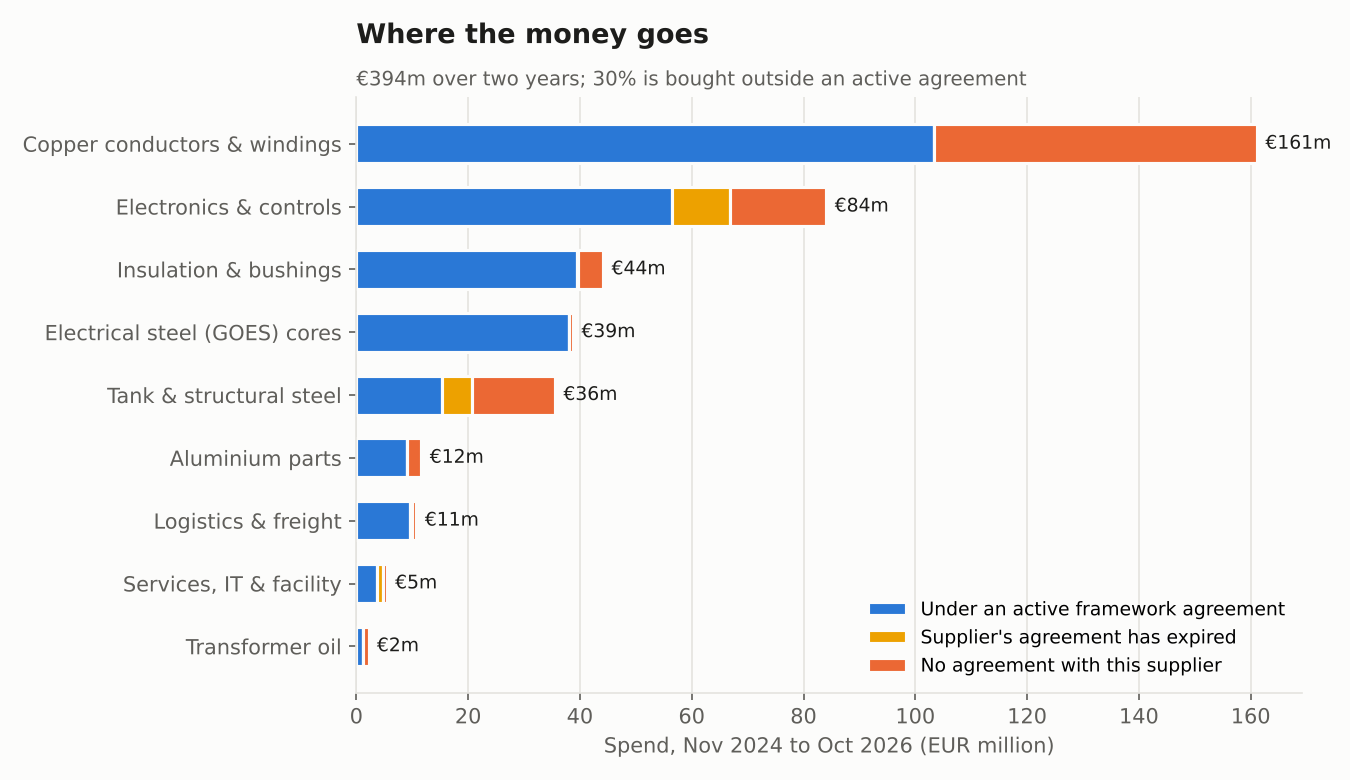

In [5]:
display(Image("outputs/figures/spend_by_category.png"))

Almost a third of spend runs outside an active agreement. Part of it is with suppliers whose agreement expired at the end of 2025, which is the quickest thing to fix.

In [6]:
A.q(con, "SELECT * FROM v_category_concentration ORDER BY hhi DESC")

,category,suppliers,hhi,top_supplier_share_pct
0,ES,6,9555.0,97.7
1,LG,12,5698.0,74.3
2,AL,8,4602.0,65.3
3,IN,16,4511.0,64.8
4,OI,4,2801.0,39.0
5,CU,10,2089.0,35.6
6,ST,14,1766.0,34.1
7,EL,19,1642.0,32.3
8,SV,29,1542.0,27.6


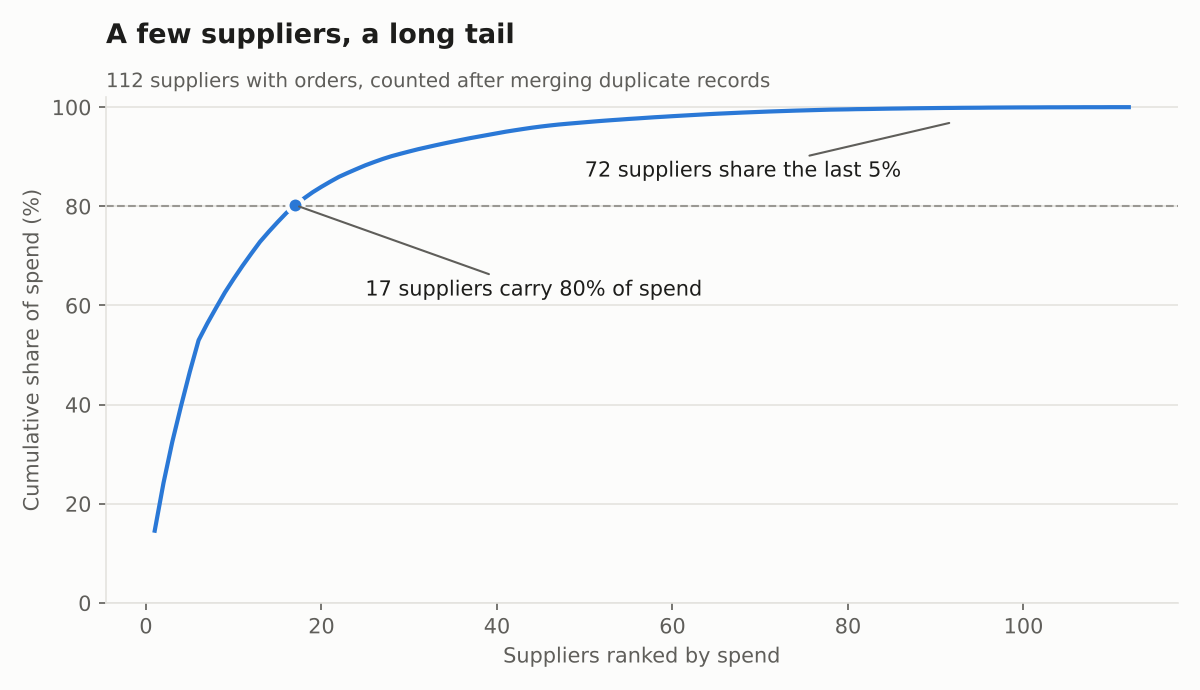

In [7]:
display(Image("outputs/figures/supplier_pareto.png"))

## Supplier scorecard and Kraljic matrix

In [8]:
sc = A.supplier_scorecard(con)
sc.head(10)[["supplier_name", "country", "spend_eur", "on_time_rate", "defect_rate", "score", "grade"]]

,supplier_name,country,spend_eur,on_time_rate,defect_rate,score,grade
5,Lech Draht A.S.,TR,57359109.0,0.788,0.0172,52.9,D
9,Pegnitz Magnetstahl Co. Ltd.,KR,37894078.0,0.989,0.0038,88.4,B
3,Mosel Draht S.A.,PL,32574021.0,0.905,0.0126,82.6,B
37,Vistula Isotech Co. Ltd.,CN,28609465.0,0.895,0.0382,47.8,D
43,Elbe Regeltechnik GmbH,AT,27152058.0,0.585,0.0319,40.3,D
1,Lech Kupferwerk Sp. z o.o.,PL,25053669.0,0.857,0.0044,84.0,B
6,Fulda Kupferwerk A.S.,TR,13402106.0,0.969,0.0027,79.3,B
52,Lech Elektronik GmbH,DE,12424538.0,0.828,0.0049,81.1,B
13,Fulda Blechwerk AG,DE,12128090.0,0.843,0.0058,81.8,B
2,Ems Leiter GmbH & Co. KG,DE,10773728.0,0.870,0.0144,78.2,B


In [9]:
vol = F.volatility(load_indices(raw))
A.kraljic(con, vol)[["category_name", "share_pct", "suppliers", "hhi", "supply_risk", "quadrant"]]

,category_name,share_pct,suppliers,hhi,supply_risk,quadrant
1,Copper conductors & windings,40.9,10,2089.0,0.528,Strategic
2,Electronics & controls,21.4,19,1642.0,0.134,Leverage
4,Insulation & bushings,11.2,16,4511.0,0.503,Strategic
3,Electrical steel (GOES) cores,9.8,6,9555.0,0.694,Strategic
7,Tank & structural steel,9.0,14,1766.0,0.406,Strategic
0,Aluminium parts,3.0,8,4602.0,0.661,Bottleneck
5,Logistics & freight,2.7,12,5698.0,0.361,Non-critical
8,"Services, IT & facility",1.4,29,1542.0,0.077,Non-critical
6,Transformer oil,0.6,4,2801.0,0.586,Bottleneck


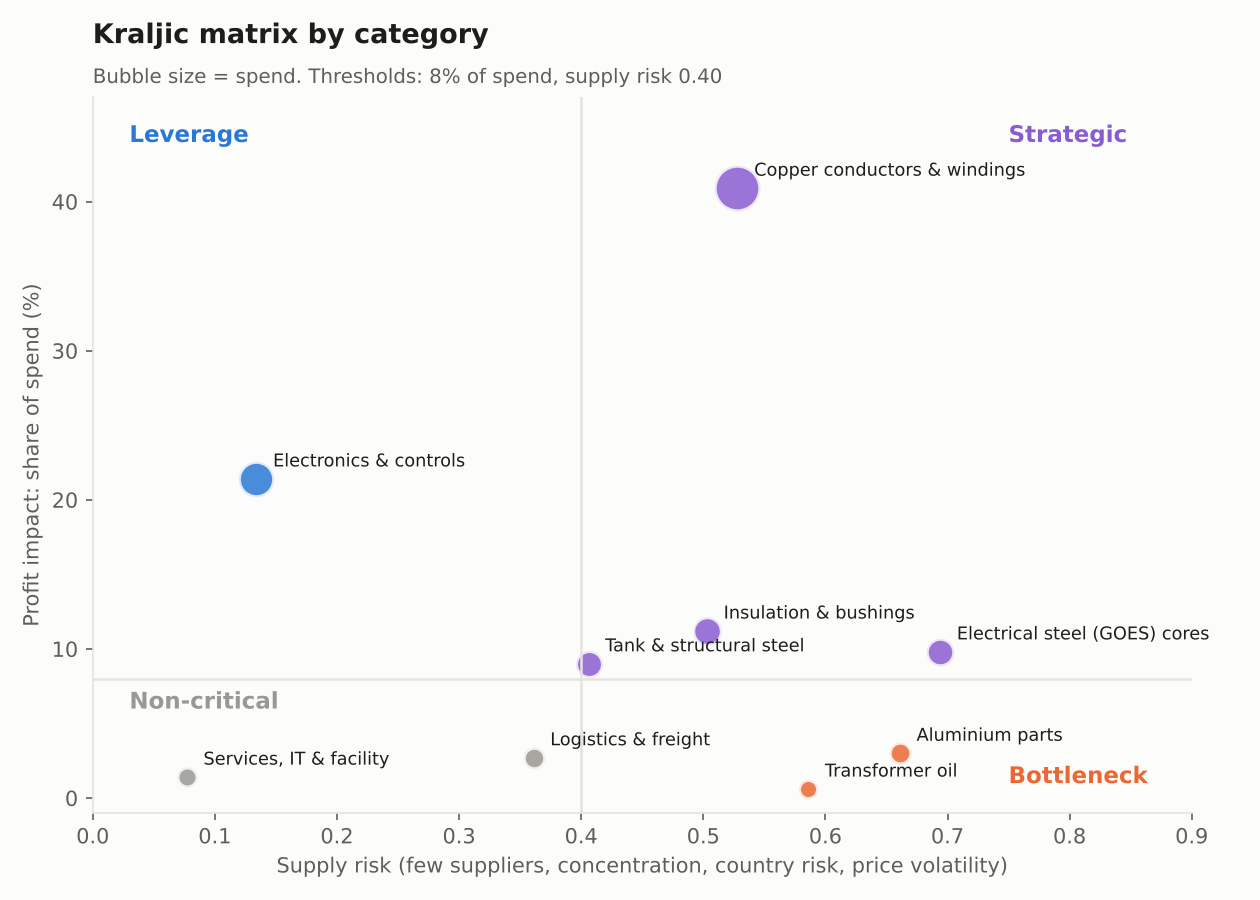

In [10]:
display(Image("outputs/figures/kraljic.png"))